In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

In [6]:
#To display the entire widht of data
pd.set_option("display.max_columns", None)
#read the csv
df = pd.read_csv("E:/melbourne-energy-analytics/data/raw/summary-residential-community-data.csv")
#basic inspection of the file
print(df.shape)
df.head()



(224, 26)


,year,postcode,suburb,category,emission_source,total_electricity_kwh,total_gas_gj,average_intensity_kwh_per_customer_per_annum,average_intensity_gj_per_customer_per_annum,average_intensity_kwh_per_customer_per_day,average_intensity_mj_per_customer_per_day,scope_1_kg_co2e,scope_2_kg_co2e,scope_3_kg_co2e,total_emissions_kg_co2e,average_emissions_per_customer_kg_co2e,average_emissions_energy_per_customer_kg_co2e_per_day,rest_of_municipality_total_electricity_kwh,rest_of_municipality_total_gas_gj,rest_of_municipality_emissions_kg_co2e,total_cost,average_intensity_household_per_day,average_intensity_household_per_month,average_intensity_household_per_annum,geo_shape,geo_point_2d
0,2020,3156,Lysterfield South,Residential,Electricity,2421938.0,NaN,9244.0,NaN,25.0,NaN,NaN,2373499.0,266413.0,2639912.0,10076.0,27.0,522087258.0,NaN,415346425.0,673828.394374,7.046203,214.322008,2571.864101,"{""coordinates"": [[[145.2890283559, -37.9628349...","-37.952494433947635, 145.26696070561252"
1,2022,3156,Lysterfield South,Residential,Gas,NaN,13345.0,NaN,58.0,NaN,159.0,687716.0,NaN,53383.0,741100.0,3236.0,8.0,NaN,6432573.0,357200787.0,417302.110630,4.992548,151.856663,1822.279959,"{""coordinates"": [[[145.2890283559, -37.9628349...","-37.952494433947635, 145.26696070561252"
2,2023,3156,Lysterfield South,Residential,Gas,NaN,13345.0,NaN,58.0,NaN,159.0,687716.0,NaN,53383.0,741100.0,3239.0,8.0,NaN,5569375.0,309267411.0,570217.598235,6.827972,207.684149,2492.209782,"{""coordinates"": [[[145.2890283559, -37.9628349...","-37.952494433947635, 145.26696070561252"
3,2024,3156,Lysterfield South,Residential,Electricity,2244760.0,NaN,8633.0,NaN,23.0,NaN,NaN,1728465.0,202028.0,1930494.0,7424.0,20.0,568025735.0,NaN,488502132.0,824526.203492,8.688369,264.271219,3171.254629,"{""coordinates"": [[[145.2890283559, -37.9628349...","-37.952494433947635, 145.26696070561252"
4,2024,3156,Lysterfield South,Residential,Gas,NaN,13345.0,NaN,58.0,NaN,159.0,687716.0,NaN,53383.0,741100.0,3239.0,8.0,NaN,5406239.0,300208467.0,570217.598235,6.827972,207.684149,2492.209782,"{""coordinates"": [[[145.2890283559, -37.9628349...","-37.952494433947635, 145.26696070561252"


In [4]:
#creating residential data frame
residential = df[df["category"] == "Residential"].copy()

print(residential.shape)

(140, 26)


In [5]:
residential["emission_source"].value_counts()

emission_source
Electricity    70
Gas            70
Name: count, dtype: int64

In [8]:
print("Rows", residential.shape[0])
print("Columns", residential.shape[1])

print("\nDuplicate Rows")
print(residential.duplicated().sum())

print("\nMissing Values")
print(residential.isnull().sum())

print("\nDatatype")
print(residential.dtypes)


Rows 140
Columns 26

Duplicate Rows
0

Missing Values
year                                                      0
postcode                                                  0
suburb                                                    0
category                                                  0
emission_source                                           0
total_electricity_kwh                                    70
total_gas_gj                                             73
average_intensity_kwh_per_customer_per_annum             70
average_intensity_gj_per_customer_per_annum              74
average_intensity_kwh_per_customer_per_day               70
average_intensity_mj_per_customer_per_day                74
scope_1_kg_co2e                                          73
scope_2_kg_co2e                                          70
scope_3_kg_co2e                                           1
total_emissions_kg_co2e                                   2
average_emissions_per_customer_kg_co2e        

In [10]:
#Separate Electricity and Gas

electricity = residential[residential["emission_source"] == "Electricity"].copy()
gas = residential[residential["emission_source"] == "Gas"].copy()

print("Electricity", electricity.shape)
print("Gas", gas.shape)

Electricity (70, 26)
Gas (70, 26)


"Which Melbourne suburbs consume the most residential electricity?"

In [11]:
suburb_electricity = (electricity.groupby("suburb")["total_electricity_kwh"].sum().sort_values(ascending=False))
print(suburb_electricity)

suburb
Botanic Ridge, Cannons Creek, Cranbourne, Cranbourne East, Cranbourne North, Cranbourne South, Cranbourne West, Devon Meadows and Junction Village    777789613.0
Berwick and Harkaway                                                                                                                                  423437256.0
Narre Warren and Narre Warren South                                                                                                                   405733511.0
Clyde and Clyde North                                                                                                                                 280741103.0
Endeavour Hills                                                                                                                                       185324478.0
Hampton Park                                                                                                                                          153676252.0
Lynbrook and Lyndhurs

C:\Users\athit\AppData\Local\Temp\ipykernel_18892\929713125.py:14: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


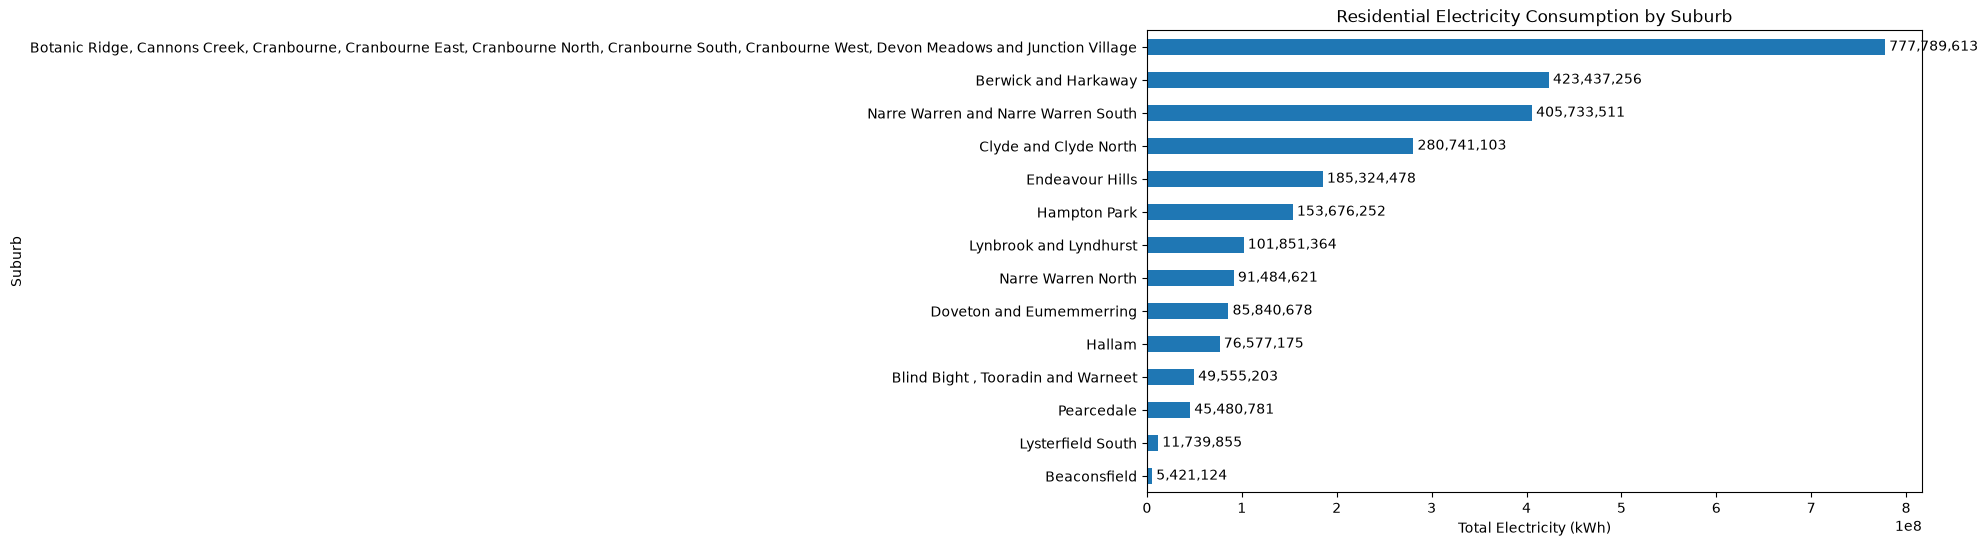

In [14]:


plt.figure(figsize=(10, 6))

# Capture the plot object in a variable called 'ax'
ax = suburb_electricity.sort_values().plot(kind="barh")

plt.title("Residential Electricity Consumption by Suburb")
plt.xlabel("Total Electricity (kWh)")
plt.ylabel("Suburb")

# Add the data labels right onto the bars
# fmt="{:,.0f}" adds commas to big numbers (e.g., 780,000,000) instead of scientific notation
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)

plt.tight_layout()
plt.show()

Botanic Ridge, Cranbourne, and surrounding areas consumed 777,789,631 kWh of residential electricity

2.Is this driven by higher consumption per household, or simply a larger number of households? 

In [15]:
suburb_comparison = (
    electricity
    .groupby("suburb")
    .agg(
        total_electricity_kwh=("total_electricity_kwh", "sum"),
        avg_electricity_per_customer=(
            "average_intensity_kwh_per_customer_per_annum",
            "mean"
        )
    )
    .sort_values("total_electricity_kwh", ascending=False)
)

print(suburb_comparison)

                                                    total_electricity_kwh  \
suburb                                                                      
Botanic Ridge, Cannons Creek, Cranbourne, Cranb...            777789613.0   
Berwick and Harkaway                                          423437256.0   
Narre Warren and Narre Warren South                           405733511.0   
Clyde and Clyde North                                         280741103.0   
Endeavour Hills                                               185324478.0   
Hampton Park                                                  153676252.0   
Lynbrook and Lyndhurst                                        101851364.0   
Narre Warren North                                             91484621.0   
Doveton and Eumemmerring                                       85840678.0   
Hallam                                                         76577175.0   
Blind Bight , Tooradin and Warneet                             49555203.0   

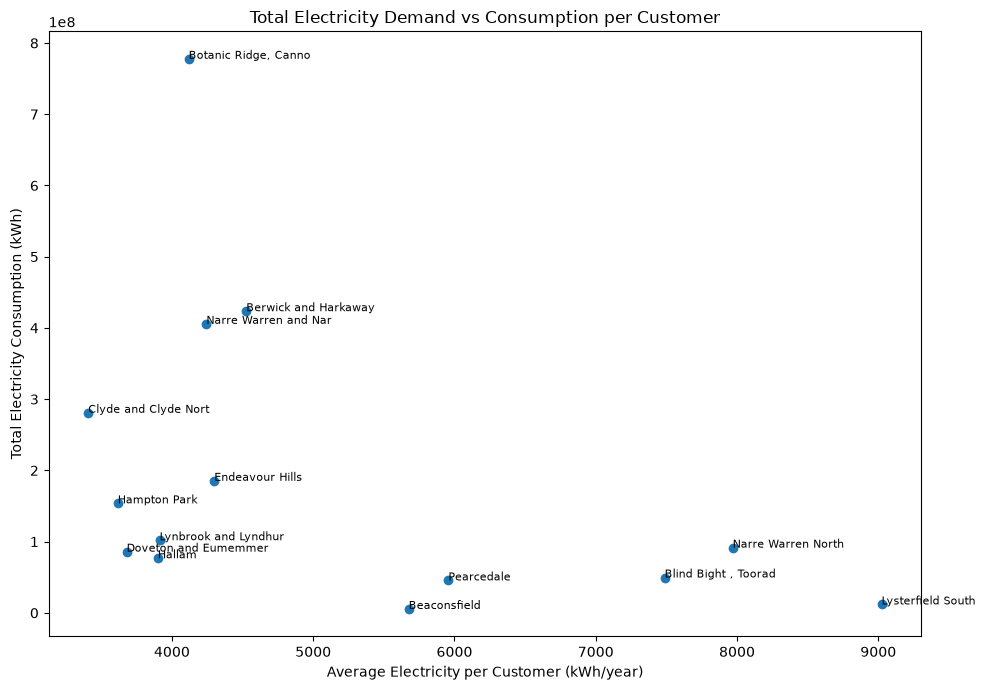

In [16]:
plt.figure(figsize=(10, 7))

plt.scatter(
    suburb_comparison["avg_electricity_per_customer"],
    suburb_comparison["total_electricity_kwh"]
)

for suburb, row in suburb_comparison.iterrows():
    plt.annotate(
        suburb[:20],
        (
            row["avg_electricity_per_customer"],
            row["total_electricity_kwh"]
        ),
        fontsize=8
    )

plt.title("Total Electricity Demand vs Consumption per Customer")
plt.xlabel("Average Electricity per Customer (kWh/year)")
plt.ylabel("Total Electricity Consumption (kWh)")

plt.tight_layout()
plt.show()

1.Regions like Botanic Ridge, Cannons Creek, and Cranbourne record the highest total residential electricity consumption in the dataset at over 777.7 million kWh. However, their average consumption per customer sits at a moderate 4,118 kWh per annum. This indicates that their massive total footprint is a product of rapid suburban expansion and a high concentration of households rather than individual energy-intensive homes.

2.Conversely, lower-density or rural-urban fringe locations like Lysterfield South record minimal aggregate consumption (approx. 11.7 million kWh), yet exhibit the highest average consumption per customer at over 9,023 kWh annually. This pattern points to fewer total properties utilizing significantly more energy per household, likely influenced by larger floor plans, property layouts, or distinct heating and cooling profiles.

3.Is residential electricity consumption increasing or decreasing?

In [17]:
yearly_electricity = (electricity.groupby("year")["total_electricity_kwh"].sum())
print(yearly_electricity)

year
2020    525223259.0
2021    524509190.0
2022    545699506.0
2023    528950570.0
2024    570270489.0
Name: total_electricity_kwh, dtype: float64


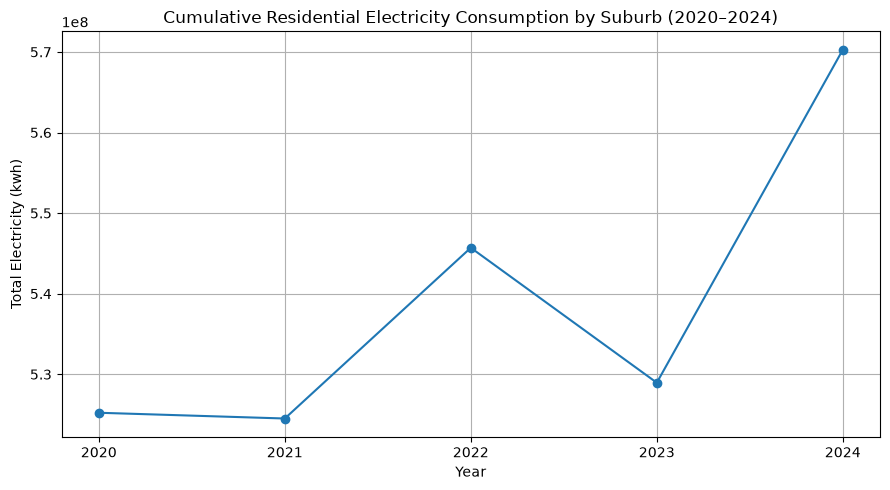

In [41]:
plt.figure(figsize=(9,5))

yearly_electricity.plot(kind = "line", marker = "o" )

plt.title("Cumulative Residential Electricity Consumption by Suburb (2020–2024)")

plt.xlabel("Year")
plt.ylabel("Total Electricity (kwh)")
plt.xticks(yearly_electricity.index)
plt.grid(True)

plt.tight_layout()
plt.show()

Residential electricity consumption remained relatively stable between 2020 and 2021, increased in 2022, declined in 2023, and reached a five-year high of approximately 570.3 million kWh in 2024.

**Cost analysis**



In [25]:
yearly_cost = (electricity.groupby("year")["total_cost"].sum())
print(yearly_cost)

formatted_cost = yearly_cost.map("${:,.2f}".format)

print(formatted_cost)

year
2020    1.632551e+08
2021    1.965756e+08
2022    2.065616e+08
2023    2.228100e+08
2024    2.382415e+08
Name: total_cost, dtype: float64
year
2020    $163,255,064.21
2021    $196,575,570.60
2022    $206,561,592.21
2023    $222,810,015.10
2024    $238,241,532.95
Name: total_cost, dtype: str


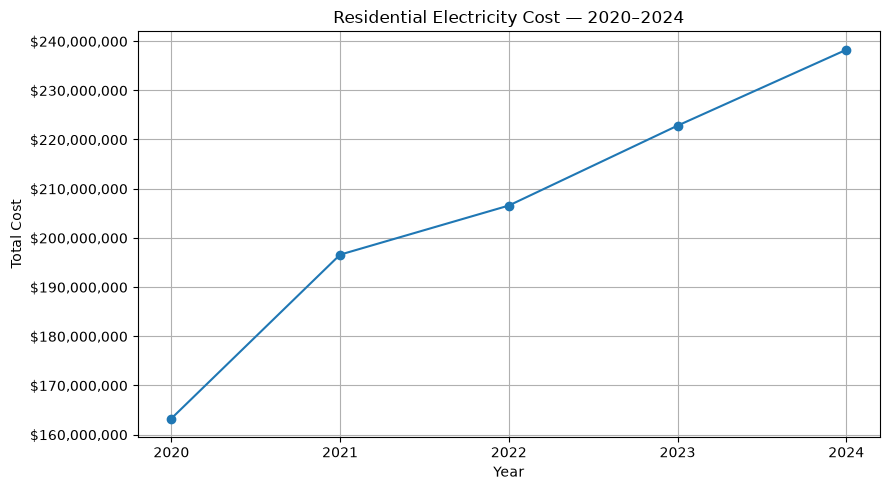

In [32]:
plt.figure(figsize=(9, 5))

yearly_cost.plot(
    kind="line",
    marker="o"
)

plt.title("Residential Electricity Cost — 2020–2024")
plt.xlabel("Year")
plt.ylabel("Total Cost")
plt.xticks(yearly_cost.index)
plt.grid(True)

# Automatically formats the y-axis numbers with dollar signs and commas
formatter = ticker.StrMethodFormatter("${x:,.0f}")
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

Electricity costs increased substantially faster than electricity consumption between 2020 and 2024, indicating that changes in the effective cost per kWh were a major contributor to rising total costs.

In [37]:
cost_per_kwh = (
    electricity.groupby("year")["total_cost"].sum()
    /
    electricity.groupby("year")["total_electricity_kwh"].sum()
)
formatted_cost_per_kwh = cost_per_kwh.map("${:,.4f}".format)
print(formatted_cost_per_kwh)

year
2020    $0.3108
2021    $0.3748
2022    $0.3785
2023    $0.4212
2024    $0.4178
dtype: str


It proves that electricity got more expensive over time. Even in years when total usage dipped slightly, the unit price per kilowatt-hour kept climbing, showing that rising energy tariffs rather than just usage volume were a major driver of higher household bills.

**Household energy intensity**

In [43]:
top_intensity = (
    electricity[
    [
        "year",
        "suburb",
        "average_intensity_household_per_annum"
    ]
].sort_values(
    "average_intensity_household_per_annum",
    ascending=False
).head(10)

   )

print(top_intensity)

     year                              suburb  \
3    2024                   Lysterfield South   
72   2023                   Lysterfield South   
140  2021                   Lysterfield South   
173  2024                  Narre Warren North   
171  2023                  Narre Warren North   
85   2021                  Narre Warren North   
222  2024  Blind Bight , Tooradin and Warneet   
139  2023  Blind Bight , Tooradin and Warneet   
169  2022                  Narre Warren North   
64   2021  Blind Bight , Tooradin and Warneet   

     average_intensity_household_per_annum  
3                              3171.254629  
72                             3070.982822  
140                            3035.659228  
173                            2888.495887  
171                            2834.010254  
85                             2705.207170  
222                            2675.405944  
139                            2645.270961  
169                            2643.917979  
64        

**Emissions**

In [39]:
suburb_emissions = (
    residential
    .groupby("suburb")["total_emissions_kg_co2e"]
    .sum()
    .sort_values(ascending=False)
)

print(suburb_emissions)

suburb
Botanic Ridge, Cannons Creek, Cranbourne, Cranbourne East, Cranbourne North, Cranbourne South, Cranbourne West, Devon Meadows and Junction Village    1.202890e+09
Berwick and Harkaway                                                                                                                                  6.773869e+08
Narre Warren and Narre Warren South                                                                                                                   6.663076e+08
Clyde and Clyde North                                                                                                                                 4.472901e+08
Endeavour Hills                                                                                                                                       3.219544e+08
Hampton Park                                                                                                                                          2.513688e+08
Lynbrook and Ly

C:\Users\athit\AppData\Local\Temp\ipykernel_18892\1653211294.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


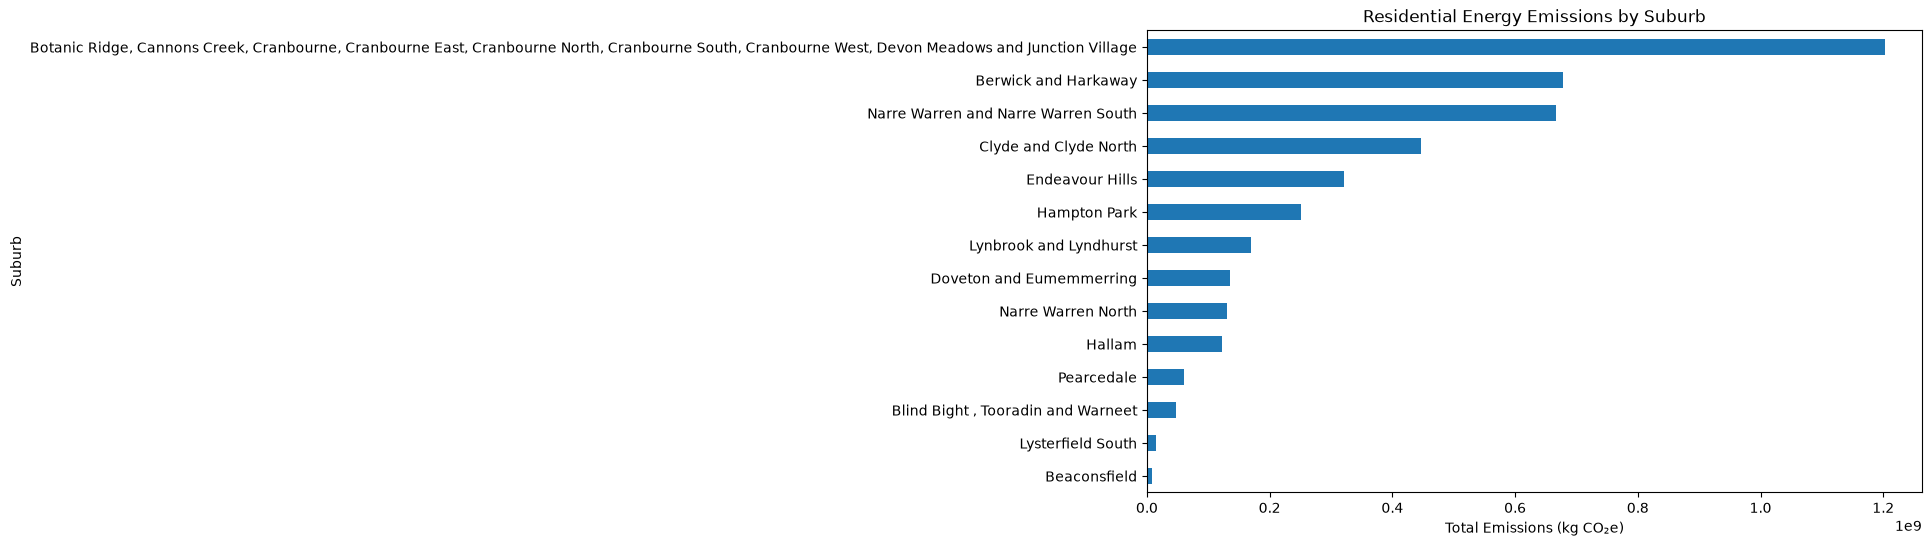

In [40]:
plt.figure(figsize=(10, 6))

suburb_emissions.sort_values().plot(kind="barh")

plt.title("Residential Energy Emissions by Suburb")
plt.xlabel("Total Emissions (kg CO₂e)")
plt.ylabel("Suburb")

plt.tight_layout()
plt.show()

In [44]:
annual_analysis = pd.DataFrame({
    "electricity_kwh": yearly_electricity,
    "total_cost": yearly_cost,
    "cost_per_kwh": cost_per_kwh
})

annual_analysis["consumption_yoy_%"] = (
    annual_analysis["electricity_kwh"]
    .pct_change() * 100
)

annual_analysis["cost_yoy_%"] = (
    annual_analysis["total_cost"]
    .pct_change() * 100
)

annual_analysis["cost_per_kwh_yoy_%"] = (
    annual_analysis["cost_per_kwh"]
    .pct_change() * 100
)

print(annual_analysis.round(3))

      electricity_kwh    total_cost  cost_per_kwh  consumption_yoy_%  \
year                                                                   
2020      525223259.0  1.632551e+08         0.311                NaN   
2021      524509190.0  1.965756e+08         0.375             -0.136   
2022      545699506.0  2.065616e+08         0.379              4.040   
2023      528950570.0  2.228100e+08         0.421             -3.069   
2024      570270489.0  2.382415e+08         0.418              7.812   

      cost_yoy_%  cost_per_kwh_yoy_%  
year                                  
2020         NaN                 NaN  
2021      20.410              20.574  
2022       5.080               1.000  
2023       7.866              11.282  
2024       6.926              -0.822  
